# 基于机器学习的交易策略

本 Notebook 根据原文 ML-Based Trading Strategy 整理。数据接口改用天勤 TqSdk，标的为螺纹钢主力连续。

⚠️ 本 Notebook 只是历史数据上的教学演示，不构成投资建议。

## 1. 数据准备

本节使用日内数据，即使用天勤 TqSdk 拉取 2020-06-08 至 2020-06-13 螺纹钢主力连续 `KQ.m@SHFE.rb` 的 10 分钟 K 线。

本 Notebook 考虑换仓的手续费（transaction cost）。 原书用外汇点差 0.00012 除以均价；这里改用上期所螺纹钢交易手续费 0.1‰（成交金额的万分之一）直接当作 `ptc`。期货公司加价和平今加收未计入。

与前面介绍的基础向量化回测相比，本例还会更深入地分析策略的风险特征。


In [1]:
from datetime import date
from pathlib import Path
import configparser

import pandas as pd
from tqsdk import TqApi, TqAuth, TqSim, TqBacktest
from tqsdk.exceptions import BacktestFinished

CFG_PATH = Path("tqsdk.cfg")
config = configparser.ConfigParser()
if not config.read(CFG_PATH, encoding="utf-8"):
    raise FileNotFoundError(f"未找到 {CFG_PATH.resolve()}，请先完成 tqsdk.cfg 配置")

TQ_USER = config.get("tqsdk", "user", fallback="").strip()
TQ_PASS = config.get("tqsdk", "password", fallback="").strip()
if not TQ_USER or not TQ_PASS:
    raise ValueError("tqsdk.cfg 中 [tqsdk] 的 user / password 不能为空")


def make_api(**kwargs):
    kwargs.setdefault("account", TqSim(init_balance=1_000_000))
    return TqApi(auth=TqAuth(TQ_USER, TQ_PASS), **kwargs)


print("已读取凭证：", TQ_USER)


已读取凭证： 故乡的原风景


在使用天勤量化之前，默认您已经知晓并同意以下免责条款，如果不同意请立即停止使用：https://www.shinnytech.com/blog/disclaimer/


In [2]:
# 天勤无外汇，改用螺纹钢主力连续。日期与周期对照原书。
instrument = "KQ.m@SHFE.rb"
start, end = date(2020, 6, 8), date(2020, 6, 13)
bar_seconds = 600  # 对应原书 granularity='M10'

with make_api(
    account=TqSim(init_balance=1_000_000),
    backtest=TqBacktest(start_dt=start, end_dt=end),
    disable_print=True,
) as api:
    klines = api.get_kline_serial(instrument, bar_seconds, data_length=800)
    try:
        while True:
            api.wait_update()
    except BacktestFinished:
        pass
    k = klines[klines["close"].notna()].copy()

t = (
    pd.to_datetime(k["datetime"], unit="ns", utc=True)
    .dt.tz_convert("Asia/Shanghai")
    .dt.tz_localize(None)
)

# 列名对齐原书 o/h/l/c/volume/complete，便于后续单元格原样对照
raw = pd.DataFrame(
    {
        "open": k["open"].values,
        "close": k["close"].values,
        "high": k["high"].values,
        "low": k["low"].values,
        "volume": k["volume"].values.astype(int),
        "complete": True,
    },
    index=t,
)
if len(raw):
    raw.iloc[-1, raw.columns.get_loc("complete")] = False

raw.tail()

,open,close,high,low,volume,complete
datetime,,,,,,
2020-06-12 22:10:00,3629.0,3629.0,3632.0,3627.0,14139,True
2020-06-12 22:20:00,3629.0,3626.0,3632.0,3623.0,29183,True
2020-06-12 22:30:00,3626.0,3623.0,3626.0,3621.0,26257,True
2020-06-12 22:40:00,3623.0,3626.0,3628.0,3618.0,33799,True
2020-06-12 22:50:00,3626.0,3628.0,3628.0,3623.0,27888,False


In [3]:
raw.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 800 entries, 2020-05-13 09:50:00 to 2020-06-12 22:50:00
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   open      800 non-null    float64
 1   close     800 non-null    float64
 2   high      800 non-null    float64
 3   low       800 non-null    float64
 4   volume    800 non-null    int64  
 5   complete  800 non-null    bool   
dtypes: bool(1), float64(4), int64(1)
memory usage: 38.3 KB


绘制收盘价折线。此处为螺纹钢主力连续。


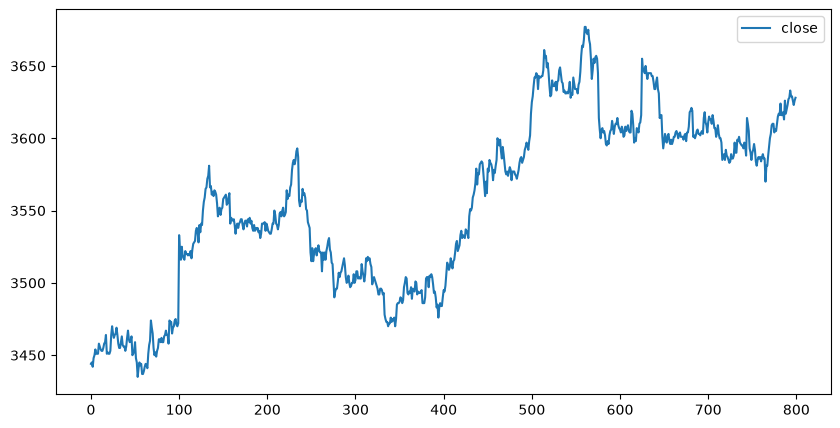

In [4]:
raw['close'].reset_index(drop=True).plot(figsize=(10, 5), legend=True);


## 2. 构造特征与预测目标

策略使用多种时间序列特征，包括对数收益率、波动率、动量、简单移动平均，以及收盘价的滚动最小值和最大值。

随后对这些特征进行滞后处理，使模型根据过去的数据模式预测市场方向，而不是直接使用当前时点之后的信息。

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data = pd.DataFrame(raw['close'])
data.columns = [instrument,]

window = 20
data['return'] = np.log(data / data.shift(1))
data['volumn'] = data['return'].rolling(window).std()
data['momentum'] = np.sign(data['return'].rolling(window).mean())
data['sma'] = data[instrument].rolling(window).mean()
data['min'] = data[instrument].rolling(window).min()
data['max'] = data[instrument].rolling(window).max()

data.dropna(inplace=True)
data

,KQ.m@SHFE.rb,return,volumn,momentum,sma,min,max
datetime,,,,,,,
2020-05-13 21:20:00,3451.0,-0.000290,0.001225,1.0,3452.80,3442.0,3464.0
2020-05-13 21:30:00,3451.0,0.000000,0.001225,1.0,3453.10,3442.0,3464.0
2020-05-13 21:40:00,3453.0,0.000579,0.001208,1.0,3453.65,3448.0,3464.0
2020-05-13 21:50:00,3464.0,0.003181,0.001342,1.0,3454.45,3450.0,3464.0
2020-05-13 22:00:00,3470.0,0.001731,0.001382,1.0,3455.45,3451.0,3470.0
...,...,...,...,...,...,...,...
2020-06-12 22:10:00,3629.0,0.000000,0.001434,1.0,3619.40,3605.0,3633.0
2020-06-12 22:20:00,3626.0,-0.000827,0.001456,1.0,3620.40,3605.0,3633.0
2020-06-12 22:30:00,3623.0,-0.000828,0.001472,1.0,3621.30,3610.0,3633.0


特征含义

- `return`：收盘价的对数收益率。
- `volumn`：过去 20 根 K 线对数收益率的滚动标准差。
- `momentum`：过去 20 根 K 线平均对数收益率的符号，用于表示动量方向。
- `sma`：过去 20 根 K 线收盘价的简单移动平均。
- `min` / `max`：过去 20 根 K 线收盘价的滚动最小值与最大值。


In [6]:
lags = 6
features = ['return', 'volumn', 'momentum', 'sma', 'min', 'max']
cols = []

for f in features:
    for lag in range(1, lags + 1):
        col = f'{f}_lag_{lag}'
        data[col] = data[f].shift(lag)
        cols.append(col)

data.dropna(inplace=True)
# 标签：本根 K 线对数收益 > 0 为 +1，=0 或 <0 都为 -1
data['direction'] = np.where(data['return'] > 0, 1, -1)


In [7]:
len(cols)

36

In [8]:
# direction：收益>0 为 +1，否则 -1
data[cols].head(lags)

,return_lag_1,return_lag_2,return_lag_3,return_lag_4,return_lag_5,return_lag_6,volumn_lag_1,volumn_lag_2,volumn_lag_3,volumn_lag_4,...,min_lag_3,min_lag_4,min_lag_5,min_lag_6,max_lag_1,max_lag_2,max_lag_3,max_lag_4,max_lag_5,max_lag_6
datetime,,,,,,,,,,,,,,,,,,,,,
2020-05-13 22:20:00,-0.001442,0.001731,0.003181,0.000579,0.000000,-0.000290,0.001418,0.001382,0.001342,0.001208,...,3450.0,3448.0,3442.0,3442.0,3470.0,3470.0,3464.0,3464.0,3464.0,3464.0
2020-05-13 22:30:00,-0.000866,-0.001442,0.001731,0.003181,0.000579,0.000000,0.001418,0.001418,0.001382,0.001342,...,3451.0,3450.0,3448.0,3442.0,3470.0,3470.0,3470.0,3464.0,3464.0,3464.0
2020-05-13 22:40:00,0.000578,-0.000866,-0.001442,0.001731,0.003181,0.000579,0.001420,0.001418,0.001418,0.001382,...,3451.0,3451.0,3450.0,3448.0,3470.0,3470.0,3470.0,3470.0,3464.0,3464.0
2020-05-13 22:50:00,0.000289,0.000578,-0.000866,-0.001442,0.001731,0.003181,0.001420,0.001420,0.001418,0.001418,...,3451.0,3451.0,3451.0,3450.0,3470.0,3470.0,3470.0,3470.0,3470.0,3464.0
2020-05-14 09:00:00,0.001154,0.000289,0.000578,-0.000866,-0.001442,0.001731,0.001373,0.001420,0.001420,0.001418,...,3451.0,3451.0,3451.0,3451.0,3470.0,3470.0,3470.0,3470.0,3470.0,3470.0
2020-05-14 09:10:00,-0.001442,0.001154,0.000289,0.000578,-0.000866,-0.001442,0.001411,0.001373,0.001420,0.001420,...,3451.0,3451.0,3451.0,3451.0,3470.0,3470.0,3470.0,3470.0,3470.0,3470.0


标签 `direction` 的取值只看 `return` 的符号
- `return > 0` → `+1`
- `return <= 0` → `-1`

等于 0 也算 `-1`，和原书保持一致。

## 3. 训练 AdaBoost 分类器

**参考阅读**：
- 关于 `决策树` 的详细内容请阅读《机器学习（西瓜书）》中的第四章。
- 关于 `AdaBoost` 的详细内容请阅读《机器学习（西瓜书）》中的第八章。

有了特征和标签后，可以使用监督学习算法进行分类。本例使用 `DecisionTreeClassifier` 作为 AdaBoost 的基础分类器，再通过 `AdaBoostClassifier` 依次训练多棵弱分类器，最终组合成一个集成模型。

**决策树参数**

- `max_depth=2`：限制每棵树的最大深度为 2，控制模型复杂度，使单棵树保持较弱的分类能力。
- `min_samples_leaf=15`：每个叶节点至少包含 15 个训练样本，避免树划分得过细，降低模型对局部噪声的敏感度。
- `random_state=100`：固定随机种子，便于复现实验结果。

这里使用浅层决策树作为基学习器。单棵树可能无法捕捉复杂的市场规律，但 AdaBoost 可以通过多轮训练、调整样本权重，并组合各轮分类结果来提升整体预测能力。

**AdaBoost 参数**

- `n_estimators=15`：最多训练 15 个基础分类器。增加数量可能提升模型的表达能力，但也会增加计算成本，并不保证样本外表现更好。
- `estimator=dtc`：指定基础分类器为上面定义的决策树。
- `random_state=100`：固定模型中的随机过程，便于复现实验。

AdaBoost 并不是简单地平均多棵树的预测结果。每一轮训练都会根据前一轮的分类表现调整样本权重，后续分类器会更加关注此前难以正确分类的样本，最终按照各分类器的表现加权组合预测结果。

**版本兼容性**

旧版本 scikit-learn 使用 `base_estimator` 指定基础分类器；scikit-learn 1.2 及之后的版本改用 `estimator`。本例采用新参数名。


**训练完成后应关注什么？**

1. **泛化能力：** 比较训练集与测试集的准确率。如果训练集表现明显更好，需要进一步检查过拟合的可能性。
2. **特征重要性：** 检查模型依赖哪些特征，并确认这些特征在预测时确实可用，没有引入未来信息。
3. **样本外表现：** 准确率只是分类指标，还需要结合交易成本、仓位管理和回测结果，判断预测信号是否具有实际价值。

注意：AdaBoost 的集成机制并不保证消除过拟合。对于金融时间序列，最终仍应以严格按时间划分、避免未来信息泄漏的样本外测试为主要依据。

In [9]:
from sklearn.metrics import accuracy_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier

random_state = 100
max_depth = 2
min_samples_leaf = 15

dtc = DecisionTreeClassifier(
    random_state=random_state,
    max_depth=max_depth,
    min_samples_leaf=min_samples_leaf
)

n_estimators = 15

# 原书参数名 base_estimator；scikit-learn>=1.2 改为 estimator
model = AdaBoostClassifier(
    estimator=dtc,
    n_estimators=n_estimators,
    random_state=random_state
)

将数据按时间顺序切分，前 70% 用作训练集，后 30% 用作测试集。标准化所需的均值和标准差只从训练集计算，再应用到训练集和测试集，避免使用测试集统计量。

In [10]:
split = int(len(data) * 0.7)
train = data.iloc[:split].copy()
mu, std = train.mean(), train.std()
train_ = (train - mu) / std

model.fit(train_[cols], train['direction'])

,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.Support for sample weighting is required, as well as proper``classes_`` and ``n_classes_`` attributes. If ``None``, thenthe base estimator is :class:`~sklearn.tree.DecisionTreeClassifier`initialized with `max_depth=1`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",DecisionTreeC...dom_state=100)
,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",15
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",100
,"learning_rate learning_rate: float, default=1.0Weight applied to each classifier at each boosting iteration. A higherlearning rate increases the contribution of each classifier. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",1.0
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](2,)","[-1, 1]"
estimator_ estimator_: estimatorThe base estimator from which the ensemble is grown... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,DecisionTreeClassifier,DecisionTreeC...dom_state=100)
estimator_errors_ estimator_errors_: ndarray of floatsClassification error for each estimator in the boostedensemble.,"ndarray[float64](15,)","[0.41,0.41,0.44,...,0.45,0.45,0.42]"
estimator_weights_ estimator_weights_: ndarray of floatsWeights for each estimator in the boosted ensemble.,"ndarray[float64](15,)","[0.36,0.36,0.25,...,0.2 ,0.19,0.32]"
estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators.,list,"[DecisionTreeC...ate=186422792), DecisionTreeC...ate=735107864), DecisionTreeC...te=1195587395), DecisionTreeC...te=1769725799), ...]"
"feature_importances_ feature_importances_: ndarray of shape (n_features,)The impurity-based feature importances if supported by the``estimator`` (when based on decision trees).Warning: impurity-based feature importances can be misleading forhigh cardinality features (many unique values). See:func:`sklearn.inspection.permutation_importance` as an alternative.","ndarray[float64](36,)","[0.11,0.08,0.06,...,0. ,0. ,0. ]"


In [11]:
train['strategy_pos'] = model.predict(train_[cols])

In [12]:
# 计算模型在训练集上的准确率：
accuracy_score(train['direction'], train['strategy_pos'])

0.6931608133086876

In [13]:
# 在测试集上评估模型。测试集使用训练集的均值和标准差进行标准化。
test = data.iloc[split:].copy()
test_ = (test - mu) / std
test['strategy_pos'] = model.predict(test_[cols])

accuracy_score(test['direction'], test['strategy_pos'])

0.5064377682403434

准确率高于 50%，但优势并不大，而且训练集与测试集的表现差距明显，可能提示过拟合或样本外表现较弱。

在金融交易中，准确率也可称为命中率，但命中率只是评估交易策略的一部分。交易是否盈利还取决于收益大小、交易时机以及交易成本。必须通过回测进一步评估策略表现。


## 4. 向量化回测

列名约定：

- `return`：标的当期对数收益，也就是买入持有每一根 10 分钟 K 线的收益。
- `strategy_pos`：分类器输出，当作策略仓位，取值只有 +1 或 -1。
- `strategy_return`：策略当期对数收益，`strategy_pos * return`。
- `strategy_tc`：扣掉换仓成本后的策略当期对数收益。

策略收益由预测仓位乘以市场对数收益率得到。每当仓位发生变化，就认为发生了一次交易，并从该期策略对数收益中扣除比例交易成本 `ptc`（上期所螺纹钢为 0.1‰）。

原文指出，较大的市场波动对策略结果可能有很大影响：能否正确判断幅度较大的上涨或下跌，比单纯追求较高命中率更重要。

### 4.1. 累计收益率


In [14]:
test['strategy_return'] = test['strategy_pos'] * test['return']
rebalance = sum(test['strategy_pos'].diff() != 0)
print(rebalance)

55


将仓位变化视为交易发生的时点，并扣除比例交易成本 `ptc`。原书是外汇点差 0.00012 除以均价，约为 0.000106。螺纹钢改用上期所官方手续费：成交金额的 0.1‰，也就是万分之一。仓位每变一次扣一次。

In [15]:
# 上期所收费：螺纹钢交易手续费为成交金额的 0.1‰
ptc = 0.0001

In [16]:
test['strategy_tc'] = np.where(
    test['strategy_pos'].diff() != 0,
    test['strategy_return'] - ptc,
    test['strategy_return']
)

test[['return', 'strategy_return', 'strategy_tc']].sum().apply(np.exp)

return             0.989905
strategy_return    1.028273
strategy_tc        1.022633
dtype: float64

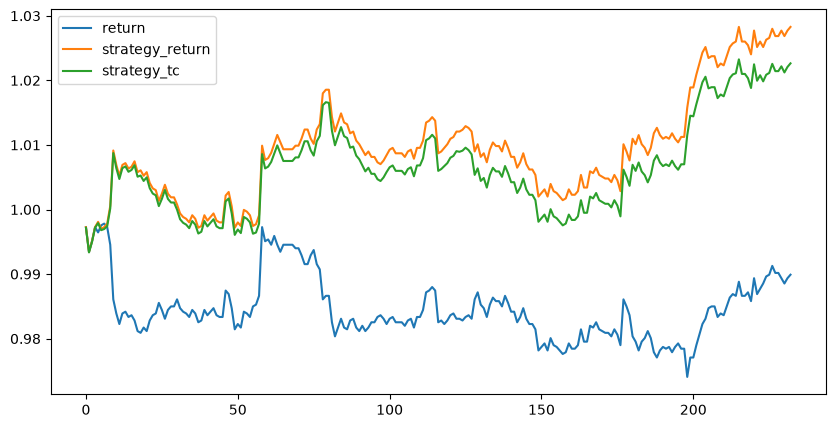

In [17]:
# 横轴用 K 线序号，避免休市空档被画成斜线
test[['return', 'strategy_return', 'strategy_tc']].cumsum().apply(np.exp).reset_index(drop=True).plot(figsize=(10, 5));

如何解读结果？

- `return`：标的累计增长因子约为 0.9899，测试区间内约下跌 1.01%。这是始终保持 1 倍多头敞口的被动基准。
- `strategy_return`：未计交易成本的策略累计增长因子约为 1.0283，约增长 2.83%。仓位来自 AdaBoost 的方向预测。比基准好，说明这几天里模型抓到的波段足以抵消标的下跌。
- `strategy_tc`：扣掉比例手续费之后约为 1.0125，约增长 1.25%。本段测试集换仓 55 次，毛利润里约有 1.58 个百分点被成本吃掉。仍高于基准，但优势已经稀薄得多。

方向预测命中率（accuracy）仅约为 50.6%，策略仍取得正收益并跑赢多头基准。这表明本段样本中，判对方向获得的收益超过了判错方向造成的损失及交易成本。命中率不能单独决定盈利能力，还需要结合盈亏幅度和交易成本判断。

本节我们使用向量化回测比较了标的收益、未计交易成本的策略收益，以及计入交易成本后的策略收益。向量化回测的局限在于它不容易直接模拟每笔交易固定收取的交易费用。可以用平均比例交易成本的倍数近似，但通常不够精确。如果需要更贴近真实交易，应考虑事件驱动回测，逐根 K 线处理交易事件。

### 4.2. 最优杠杆：Kelly 准则

连续近似下，把一根 10 分钟 K 线当作一期。该期简单收益的均值为 $m$、方差为 $s^2$，无风险利率 $r=0$，对数财富增长率取二阶展开

$$
g_{\infty}(f)=f m-\frac{1}{2}s^{2} f^{2}
$$

对 $f$ 求导得到满 Kelly 杠杆

$$
f^{*}=\frac{m}{s^{2}}
$$

这里先通过 `np.expm1()` 将测试集每根 K 线的对数收益还原为简单收益，再估算 $m$ 和 $s^{2}$。 $m/s^{2}$ 是连续近似下的 Kelly 估计，并不保证等于离散样本中使累计财富最大的精确杠杆。

无风险利率按 0 处理、也不引入借款利率 $r_{b}$，只改变最优解的公式：有 $r$ 时是 $f^{*}=(m-r)/s^{2}$，这里变成 $f^{*}=m/s^{2}$。把 $r$ 设成 0，等于假定闲置资金不生息、加杠杆也不付利息。


In [18]:
# `.mean()` 和 `.var()` 得到的是每根 10 分钟 K 线的均值和方差。
# 本例得到的数据是从 2020-05-13 拉到 2020-06-12。年化因子需要按日历跨度折算
# 独立同分布时分子分母同乘，比值不变，所以 f 不变，
# 但年化 mean，var 和 volatility 会改变。

span_days = (data.index[-1] - data.index[0]) / pd.Timedelta(days=1)
ann_factor = len(data) * 365 / span_days  

In [19]:
simple_returns = np.expm1(test[['return', 'strategy_tc']])
mean = simple_returns.mean() * ann_factor
var = simple_returns.var() * ann_factor
vol = var ** 0.5
f_star = mean / var
f_star_half = 0.5 * mean / var

kelly_table = pd.DataFrame(
    {
        'mean': mean,
        'var': var,
        'vol': vol,
        'f_star': f_star,
        'f_star_half': f_star_half,
    }
).T.rename(columns={'return': 'buy_hold', 'strategy_tc': 'strategy_tc'})
print(kelly_table.to_string(float_format=lambda x: f'{x: .4f}'))

             buy_hold  strategy_tc
mean          -0.3957       0.9180
var            0.0282       0.0283
vol            0.1681       0.1683
f_star       -14.0101      32.4271
f_star_half   -7.0050      16.2135


从年化统计来看，策略与标的的波动率较为接近。策略始终保持绝对值为 1 的多头或空头仓位，因此扣费前，两者每期对数收益的平方相同。虽然收益均值和交易成本会影响方差，但本例中这些差异较小，所以最终波动率仍然接近。具体统计值见上表。

在此基础上，使用每期简单收益的均值与方差估计 Kelly 杠杆，并比较不同杠杆下的资金曲线。正 Kelly 值表示沿策略方向配置敞口，负值表示反向配置；具体估计值见上表。


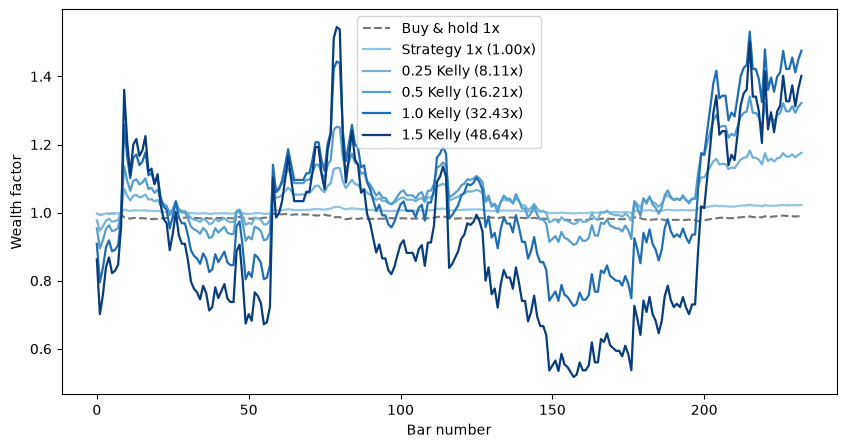

In [20]:
# 不计融资成本、保证金追缴、滑点及合约手数取整。
strategy_simple = simple_returns['strategy_tc']
full_kelly = float(f_star['strategy_tc'])
if not np.isfinite(full_kelly) or full_kelly <= 0:
    raise ValueError('当前 Kelly 估计不是正的有限值，不能沿用本例的正杠杆比较。')

levels = {
    'Strategy 1x': 1.0,
    '0.25 Kelly': 0.25 * full_kelly,
    '0.5 Kelly': 0.5 * full_kelly,
    '1.0 Kelly': full_kelly,
    '1.5 Kelly': 1.5 * full_kelly,
}


def fixed_leverage_log_returns(leverage):
    growth = 1 + leverage * strategy_simple
    if not np.isfinite(growth).all() or (growth <= 0).any():
        raise ValueError(
            f'{leverage:.2f} 倍杠杆出现非有限收益或权益耗尽，需单独处理破产情形。'
        )
    return np.log1p(leverage * strategy_simple)


# 先画灰色基准，再按杠杆从小到大绘制浅蓝至深蓝的策略曲线。
wealth = pd.DataFrame(index=test.index)
wealth['Buy & hold 1x'] = (1 + simple_returns['return']).cumprod()
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(wealth['Buy & hold 1x'].to_numpy(), '--', color='0.45', label='Buy & hold 1x')

low, high = min(levels.values()), max(levels.values())
for label, leverage in sorted(levels.items(), key=lambda item: item[1]):
    name = f'{label} ({leverage:.2f}x)'
    wealth[name] = np.exp(fixed_leverage_log_returns(leverage).cumsum())
    shade = 0.4 + 0.55 * (leverage - low) / (high - low)
    ax.plot(wealth[name].to_numpy(), color=plt.get_cmap('Blues')(shade),
            linewidth=1.6, label=name)

ax.set(xlabel='Bar number', ylabel='Wealth factor')
ax.legend()
plt.show()


杠杆图比较 1 倍、0.25倍 Kelly、半 Kelly、满 Kelly 和 1.5 倍 Kelly，刻度根据当前样本估计自动计算，并在图例中显示。

每根 K 线结束时,会根据账户资金调整仓位，来保持杠杆倍数不变。涨跌按复利累积：例如，先赚 10% 再亏 10%，变成 99%；加杠杆会放大涨跌，也会放大这种损耗。如果某一期的亏损达到或超过账户全部资金，代码就会停止并提示。杠杆越大，最终赚到的钱不一定越多；图中的满 Kelly 杠杆由 $m/s^2$ 估算：该公式对对数增长率做了二阶近似，忽略了更高阶项，并用方差近似收益的二阶矩，因此不一定恰好对应本段样本收益最高的杠杆。

测试集未参与 AdaBoost 训练，因此模型在测试集上的预测属于样本外结果。但本节又使用测试期收益估计 Kelly 杠杆，并将其应用于同一测试期，相当于看过这段行情的盈亏后再确定杠杆。因此，这张杠杆图只能用于事后分析，不能作为包含仓位管理的完整策略的独立样本外检验。要进行严格的样本外测试，应在训练期或独立校准期确定杠杆，再应用到测试期。

⚠️ 本例测试样本较短，年化收益与 Kelly 杠杆估计易受少数交易影响，仅用于方法演示。杠杆会放大风险，回测结果不足以证明策略具有长期盈利能力，也不构成收益承诺。

## 6. 风险分析：最大回撤与回撤持续时间

本节沿用前文估计的半 Kelly 杠杆作为 `risk_leverage`，以 100,000 元初始权益计算资金曲线。每根 K 线按当时权益维持固定杠杆，因此头寸规模随权益变化。这里的金额用于归一化展示，未模拟期货合约手数和保证金约束。

最大回撤是权益从此前高点下降的最大金额。回撤持续时间则是策略从一个高点开始，直到重新达到高点所经历的最长时间。

In [ ]:
# 风险分析统一采用半 Kelly
risk_leverage = levels['0.5 Kelly']
test['risk_log_return'] = fixed_leverage_log_returns(risk_leverage)

In [ ]:
equity = 100_000  # 初始权益，人民币元
risk = pd.DataFrame({'log_return': test['risk_log_return']})
risk['equity'] = np.exp(risk['log_return'].cumsum()) * equity
# 将初始权益也纳入高水位，避免遗漏第一根 K 线的亏损。
risk['cummax'] = risk['equity'].cummax().clip(lower=equity)
risk['drawdown'] = risk['cummax'] - risk['equity']
print(f'风险分析杠杆：半 Kelly = {risk_leverage:.2f} 倍')
risk['drawdown'].max()


查找最大回撤出现的时间：

In [ ]:
t_max = risk['drawdown'].idxmax()
t_max


最大回撤金额及发生时间以本次半 Kelly 资金曲线的计算结果为准，金额单位为人民币元。


In [ ]:
temp = risk['drawdown'][risk['drawdown'] == 0]
periods = (
    temp.index[1:].to_pydatetime()
    - temp.index[:-1].to_pydatetime()
)
periods[20:30]


In [ ]:
t_per = periods.max()
t_per


In [ ]:
t_per.total_seconds() / 60 / 60


这里计算相邻两次回到高水位之间的日历时间，包含休市时段；尚未恢复的期末回撤未包含在这些区间内。具体结果以本次输出为准。


In [ ]:
risk[['equity', 'cummax']].plot(figsize=(10, 6))
plt.axvline(t_max, c='r', alpha=0.5);

## 7. 风险分析：风险价值（VaR）

风险价值（Value at Risk，VaR）通常以货币金额表示，描述在给定时间范围和置信水平下，损失可能达到的分位数阈值。这里使用半 Kelly 策略的权益简单收益，计算不同置信水平下、以 10 分钟 K 线为时间区间的 VaR。

将收益率乘以初始权益，得到统一按 100,000 元本金折算的损益，VaR 金额单位为人民币元。


In [ ]:
import scipy.stats as scs

percs = [0.01, 0.1, 1., 2.5, 5.0, 10.0]
risk['return'] = np.expm1(risk['log_return'])
VaR = scs.scoreatpercentile(equity * risk['return'], percs)

def print_var():
    print('{}\n{}'.format('置信水平', '风险价值 VaR'))
    print(33 * '-')
    for pair in zip(percs, VaR):
        print('{:16.2f} {:16.3f}'.format(100 - pair[0], -pair[1]))

print_var()

随后将 10 分钟数据重采样为 1 小时数据，再计算一小时持有区间的 VaR。时间范围变长后，VaR 通常会发生变化；具体结果取决于样本中的收益分布。

In [ ]:
# 按小时汇总对数收益，再还原简单收益；无交易数据的小时不参与估计。
hourly_log_return = risk['log_return'].resample('1h', label='right').sum(min_count=1)
hourly_return = np.expm1(hourly_log_return.dropna())
VaR = scs.scoreatpercentile(equity * hourly_return, percs)

print_var()


VaR 的解释需要谨慎：它是基于历史样本和指定分位数的统计估计，并不表示损失绝不会超过该金额，也无法单独描述极端损失的严重程度。


## 8. 保存模型对象

如果回测、杠杆分析和风险分析的结果都能接受，可以将模型及其标准化参数保存下来，以便后续部署。模型对象代表机器学习交易策略的核心预测部分。

In [ ]:
import pickle

algorithm = {
    'model': model,
    'mu': mu,
    'std': std
}

with open('algorithm.pkl', 'wb') as f:
    pickle.dump(algorithm, f)

运行成功后，会在当前工作目录生成 `algorithm.pkl`，其中保存了训练好的模型、训练集均值和标准差。